In [ ]:
%pip install -q lightning-bolts
%pip install -q chemprop

In [ ]:
%pip install -q rdkit

In [ ]:
import numpy as np
import pandas as pd
from lightning import pytorch as pl
from chemprop import data, models, nn, featurizers

In [ ]:
import os
import sys
from google.colab import drive
drive.mount('/content/drive')

DRIVE_ROOT = '/content/drive/MyDrive/Research/HybridGNN/TOX'
DATA_CSV  = f'{DRIVE_ROOT}/tox21_dataset.csv'

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
df = pd.read_csv(DATA_CSV)
print(df.shape)

(7831, 14)


In [ ]:
df.head()

,NR-AR,NR-AR-LBD,NR-AhR,NR-Aromatase,NR-ER,NR-ER-LBD,NR-PPAR-gamma,SR-ARE,SR-ATAD5,SR-HSE,SR-MMP,SR-p53,mol_id,smiles
0,0.0,0.0,1.0,NaN,NaN,0.0,0.0,1.0,0.0,0.0,0.0,0.0,TOX3021,CCOc1ccc2nc(S(N)(=O)=O)sc2c1
1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,0.0,NaN,0.0,0.0,TOX3020,CCN1C(=O)NC(c2ccccc2)C1=O
2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NaN,0.0,NaN,NaN,TOX3024,CC[C@]1(O)CC[C@H]2[C@@H]3CCC4=CCCC[C@@H]4[C@H]...
3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,0.0,NaN,0.0,0.0,TOX3027,CCCN(CC)C(CC)C(=O)Nc1c(C)cccc1C
4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,TOX20800,CC(O)(P(=O)(O)O)P(=O)(O)O


In [ ]:
task_columns = df.columns
smiles = df['smiles'].values
targets = df[task_columns].values

In [ ]:
task_columns = [col for col in df.columns if col not in ['smiles', 'mol_id']]
smiles = df['smiles'].values
targets = df[task_columns].values
data_list = []
for smi, y in zip(smiles, targets):
    try:
        dp = data.MoleculeDatapoint.from_smi(smi, y)
        data_list.append(dp)
    except RuntimeError:
        continue

print("Number of molecules:", len(smiles))
print("Number of successfully parsed molecules:", len(data_list))
print("Number of tasks:", len(task_columns))

[20:01:15] WARNING: not removing hydrogen atom without neighbors
[20:01:15] Explicit valence for atom # 8 Al, 6, is greater than permitted
[20:01:16] Explicit valence for atom # 3 Al, 6, is greater than permitted
[20:01:16] Explicit valence for atom # 4 Al, 6, is greater than permitted
[20:01:16] Explicit valence for atom # 4 Al, 6, is greater than permitted
[20:01:16] Explicit valence for atom # 9 Al, 6, is greater than permitted
[20:01:16] Explicit valence for atom # 5 Al, 6, is greater than permitted
[20:01:17] Explicit valence for atom # 16 Al, 6, is greater than permitted
[20:01:17] Explicit valence for atom # 20 Al, 6, is greater than permitted


Number of molecules: 7831
Number of successfully parsed molecules: 7823
Number of tasks: 12


In [ ]:
mols = [d.mol for d in data_list]
train_indices, val_indices, test_indices =data.make_split_indices(mols,
                        split='scaffold_balanced',
                        seed = 42)

/usr/local/lib/python3.13/dist-packages/astartes/samplers/extrapolation/scaffold.py:48: NoMatchingScaffold: No matching scaffold was found for the 1775 molecules corresponding to indices {4, 5, 8, 9, 12, 13, 16, 26, 28, 29, 30, 31, 37, 38, 42, 47, 50, 51, 63, 67, 68, 70, 72, 84, 95, 98, 100, 101, 113, 115, 122, 123, 125, 126, 128, 132, 133, 137, 141, 142, 149, 150, 152, 153, 154, 169, 175, 177, 179, 181, 182, 184, 190, 191, 194, 203, 204, 208, 216, 218, 222, 229, 249, 250, 253, 255, 256, 271, 281, 284, 300, 301, 320, 321, 322, 323, 327, 336, 339, 346, 350, 360, 361, 363, 364, 365, 366, 368, 372, 376, 380, 392, 393, 396, 399, 400, 401, 404, 413, 429, 431, 435, 439, 441, 442, 454, 455, 458, 478, 479, 481, 482, 483, 484, 485, 486, 488, 489, 491, 510, 511, 512, 525, 527, 528, 529, 530, 535, 540, 542, 543, 544, 545, 546, 555, 559, 562, 563, 567, 571, 578, 580, 582, 587, 592, 593, 597, 600, 610, 614, 624, 631, 632, 633, 636, 637, 640, 642, 644, 645, 646, 648, 659, 662, 663, 665, 667, 668, 67

In [ ]:
train_data, val_data, test_data = data.split_data_by_indices(
    data_list, train_indices, val_indices, test_indices)

In [ ]:
train_data = train_data[0]
val_data = val_data[0]
test_data = test_data[0]

In [ ]:
featurizer = featurizers.SimpleMoleculeMolGraphFeaturizer()

train_dset = data.MoleculeDataset(
    train_data,
    featurizer=featurizer,
)
val_dset = data.MoleculeDataset(
    val_data,
    featurizer=featurizer,
)
test_dset = data.MoleculeDataset(
    test_data,
    featurizer=featurizer,
)

In [ ]:
train_loader =data.build_dataloader(
    train_dset,
    num_workers=4,
    shuffle =True)
val_loader =data.build_dataloader(
    val_dset,
    num_workers=4,
    shuffle =False)
test_loader =data.build_dataloader(
    test_dset,
    num_workers=4,
    shuffle =False
)

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:424: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()


In [ ]:
mp = nn.BondMessagePassing()

In [ ]:
agg = nn.MeanAggregation()
ffn = nn.BinaryClassificationFFN(input_dim=mp.output_dim, n_tasks = len(task_columns),)
model =models.MPNN(message_passing=mp, agg=agg, predictor = ffn)
print(model)

MPNN(
  (message_passing): BondMessagePassing(
    (W_i): Linear(in_features=86, out_features=300, bias=False)
    (W_h): Linear(in_features=300, out_features=300, bias=False)
    (W_o): Linear(in_features=372, out_features=300, bias=True)
    (dropout): Dropout(p=0.0, inplace=False)
    (tau): ReLU()
    (V_d_transform): Identity()
    (graph_transform): Identity()
  )
  (agg): MeanAggregation()
  (bn): Identity()
  (predictor): BinaryClassificationFFN(
    (ffn): MLP(
      (0): Sequential(
        (0): Linear(in_features=300, out_features=300, bias=True)
      )
      (1): Sequential(
        (0): ReLU()
        (1): Dropout(p=0.0, inplace=False)
        (2): Linear(in_features=300, out_features=12, bias=True)
      )
    )
    (criterion): BCELoss(task_weights=[[1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0]])
    (output_transform): Identity()
  )
  (X_d_transform): Identity()
  (metrics): ModuleList(
    (0): BinaryAUROC()
    (1): BCELoss(task_weights=[[1.0, 1.0, 1.

In [ ]:
trainer = pl.Trainer(
    accelerator = 'gpu',
    max_epochs = 50,
    devices = 1,
    logger = True,
)

INFO: GPU available: True (cuda), used: True
INFO:lightning.pytorch.utilities.rank_zero:GPU available: True (cuda), used: True
INFO: TPU available: False, using: 0 TPU cores
INFO:lightning.pytorch.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO: 💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
INFO:lightning.pytorch.utilities.rank_zero:💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.


In [ ]:
trainer.fit(model, train_loader, val_loader)

INFO: 💡 Tip: For seamless cloud uploads and versioning, try installing [litmodels](https://pypi.org/project/litmodels/) to enable LitModelCheckpoint, which syncs automatically with the Lightning model registry.
INFO:lightning.pytorch.utilities.rank_zero:💡 Tip: For seamless cloud uploads and versioning, try installing [litmodels](https://pypi.org/project/litmodels/) to enable LitModelCheckpoint, which syncs automatically with the Lightning model registry.
INFO: LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO:lightning.pytorch.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO: Loading `train_dataloader` to estimate number of stepping batches.
INFO:lightning.pytorch.utilities.rank_zero:Loading `train_dataloader` to estimate number of stepping batches.
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
/usr/local/lib/python3.13/d

┏━━━┳━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━┳━━━━━━━┓
┃   ┃ Name            ┃ Type                    ┃ Params ┃ Mode  ┃ FLOPs ┃
┡━━━╇━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━╇━━━━━━━┩
│ 0 │ message_passing │ BondMessagePassing      │  227 K │ train │     0 │
│ 1 │ agg             │ MeanAggregation         │      0 │ train │     0 │
│ 2 │ bn              │ Identity                │      0 │ train │     0 │
│ 3 │ predictor       │ BinaryClassificationFFN │ 93.9 K │ train │     0 │
│ 4 │ X_d_transform   │ Identity                │      0 │ train │     0 │
│ 5 │ metrics         │ ModuleList              │      0 │ train │     0 │
└───┴─────────────────┴─────────────────────────┴────────┴───────┴───────┘

Trainable params: 321 K                                                                                            
Non-trainable params: 0                                                                                            
Total params: 321 K                                                                                                
Total estimated model params size (MB): 1.286                                                                      
Modules in train mode: 24                                                                                          
Modules in eval mode: 0                                                                                            
Total FLOPs: 0

Output()

INFO: `Trainer.fit` stopped: `max_epochs=50` reached.
INFO:lightning.pytorch.utilities.rank_zero:`Trainer.fit` stopped: `max_epochs=50` reached.


In [ ]:
test_results =trainer.test(model, dataloaders = test_loader)

INFO: LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO:lightning.pytorch.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


Output()

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃        Test metric        ┃       DataLoader 0        ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│         test/roc          │    0.8379401564598083     │
└───────────────────────────┴───────────────────────────┘

In [ ]:
%pip install -q torch_geometric

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 64.4/64.4 kB 6.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 72.8 MB/s eta 0:00:00


In [ ]:
from torch_geometric.explain import Explainer, GNNExplainer

explainer = Explainer(
    model=model,
    algorithm=GNNExplainer(epochs=50),
    explanation_type='model',
    node_mask_type='attributes',
    edge_mask_type='object',
    model_config=dict(
        mode='binary_classification',
        task_level='graph',
        return_type='raw',
    ),
)
N_EXPLAIN_PER_TASK = 25

task_toxic_smiles = {}
for t_idx, task in enumerate(task_columns):
    candidates = [
        smi for smi, y_vec in zip(smiles, targets)
        if not np.isnan(y_vec[t_idx]) and y_vec[t_idx] == 1.0
    ]
    task_toxic_smiles[task] = candidates[:N_EXPLAIN_PER_TASK]
    print(f'{task:<15}: {len(candidates)} toxic molecules → explaining {len(task_toxic_smiles[task])}')

NR-AR          : 309 toxic molecules → explaining 25
NR-AR-LBD      : 237 toxic molecules → explaining 25
NR-AhR         : 768 toxic molecules → explaining 25
NR-Aromatase   : 300 toxic molecules → explaining 25
NR-ER          : 793 toxic molecules → explaining 25
NR-ER-LBD      : 350 toxic molecules → explaining 25
NR-PPAR-gamma  : 186 toxic molecules → explaining 25
SR-ARE         : 942 toxic molecules → explaining 25
SR-ATAD5       : 264 toxic molecules → explaining 25
SR-HSE         : 372 toxic molecules → explaining 25
SR-MMP         : 918 toxic molecules → explaining 25
SR-p53         : 423 toxic molecules → explaining 25


In [ ]:
device = next(model.parameters()).device

In [ ]:
MODEL_NAME = 'ChemProp_MPNN'
DIR_TASK_NAME = 'ALL'
RESULTS_DIR = f'{DRIVE_ROOT}/{DIR_TASK_NAME}/results_tox21/explainability/{MODEL_NAME}'

In [ ]:
def get_atom_importance(explanation):
    if explanation.node_mask is not None:
        return explanation.node_mask.sum(dim=1).cpu().numpy()
    return np.zeros(explanation.x.shape[0])


In [ ]:
from pathlib import Path
import torch
import matplotlib.pyplot as plt

from rdkit import Chem
from rdkit.Chem import Draw

os.makedirs(RESULTS_DIR, exist_ok=True)


TOP_K = 25
BATCH_SIZE = 64
N_TASKS = len(task_columns)

print(f"Explaining {N_TASKS} tasks, top {TOP_K} predictions per task")

Explaining 12 tasks, top 25 predictions per task


In [ ]:
model.eval()
test_smiles = [
    Chem.MolToSmiles(dp.mol)
    for dp in test_data]

def predict_smiles(smiles_list:list, batch_size:int=BATCH_SIZE):
    """Return an (n_molecules, n_tasks) array of predictions.
    Parameters:
    smiles_list (list): List of SMILES strings
    batch_size (int): Batch size for prediction
    Returns"""
    datapoints = [
        data.MoleculeDatapoint.from_smi(
            smi,
            np.zeros(N_TASKS, dtype=float)
        )
        for smi in smiles_list]
    dataset = data.MoleculeDataset(
        datapoints,
        featurizer=featurizer)
    loader = data.build_dataloader(
        dataset,
        batch_size=batch_size,
        shuffle=False,
        num_workers=0)

    outputs = trainer.predict(
        model,
        dataloaders=loader)

    outputs = torch.cat([
        out.detach().cpu().reshape(-1, N_TASKS)
        for out in outputs
    ], dim=0)

    outputs = outputs.numpy()
    # convert logits to probabilities if the model returned logits
    if outputs.min() < 0 or outputs.max() > 1:
        outputs = 1.0 / (1.0 + np.exp(-np.clip(outputs, -40, 40)))

    return outputs

In [ ]:
test_probs = predict_smiles(test_smiles)

assert test_probs.shape == (len(test_smiles), N_TASKS)

print("Prediction matrix:", test_probs.shape)
print("Probability range:", test_probs.min(), test_probs.max())

INFO: LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO:lightning.pytorch.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


Output()

/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.


Prediction matrix: (782, 12)
Probability range: 4.2441198e-10 0.9999778


In [ ]:
top_molecules = {}

for task_idx, task_name in enumerate(task_columns):
    probs = test_probs[:, task_idx]

    top_idx = np.argsort(probs)[::-1][:min(TOP_K, len(probs))]

    top_molecules[task_name] = [
        {
            "rank": rank,
            "test_index": int(idx),
            "smiles": test_smiles[idx],
            "probability": float(probs[idx]),
        }
        for rank, idx in enumerate(top_idx, start=1)
    ]

top_df = pd.DataFrame([
    {
        "task": task_name,
        **item
    }
    for task_name, items in top_molecules.items()
    for item in items
])

top_df.to_csv(f"{RESULTS_DIR}/top_predictions.csv", index=False)

display(top_df.head(10))

,task,rank,test_index,smiles,probability
0,NR-AR,1,426,C1C[C@@H]2[C@@H]3CC[C@H](C3)[C@@H]2C1,0.999622
1,NR-AR,2,189,C/C=C1/C(=O)C[C@H]2[C@@H]3CCC4=CC(=O)CC[C@]4(C...,0.983219
2,NR-AR,3,188,C/C=C1\C(=O)C[C@H]2[C@@H]3CCC4=CC(=O)CC[C@]4(C...,0.976288
3,NR-AR,4,523,CC(=O)S[C@@H]1CC2=CC(=O)CC[C@]2(C)[C@H]2CC[C@@...,0.835353
4,NR-AR,5,556,COC(=O)[C@@H]1CC2=CC(=O)CC[C@]2(C)[C@@]23O[C@@...,0.772823
5,NR-AR,6,292,C#C[C@]1(O)CC[C@H]2[C@@H]3CCC4=C(CCC(=O)C4)[C@...,0.735572
6,NR-AR,7,598,C=C1C[C@]23C[C@@]1(O)CC[C@H]2[C@@]12C=C[C@H](O...,0.611114
7,NR-AR,8,279,CC(=O)O[C@H]1CC[C@@]2(C)C(=CC[C@@H]3[C@@H]2CC[...,0.609749
8,NR-AR,9,291,C#C[C@]1(O)CC[C@H]2[C@@H]3[C@H](C)CC4=C(CCC(=O...,0.522666
9,NR-AR,10,540,C[C@H](CCC(=O)O)[C@H]1CC[C@H]2[C@@H]3C(=O)C[C@...,0.398439


In [ ]:
def delete_one_bond(smiles, bond_idx):
    """Return modified SMILES after deleting one bond, or None.
    Parameters:
    smiles (str): SMILES string
    bond_idx (int): Index of the bond to delete
    Returns:
    modified_smiles(str) or None: SMILES string after deletion, or None if invalid
    """
    mol = Chem.MolFromSmiles(smiles)

    if mol is None or bond_idx >= mol.GetNumBonds():
        return None

    bond = mol.GetBondWithIdx(bond_idx)
    begin_atom = bond.GetBeginAtomIdx()
    end_atom = bond.GetEndAtomIdx()

    rw_mol = Chem.RWMol(mol)
    rw_mol.RemoveBond(begin_atom, end_atom)

    modified_mol = rw_mol.GetMol()

    try:
        Chem.SanitizeMol(modified_mol)
        modified_smiles = Chem.MolToSmiles(modified_mol)

        if not modified_smiles:
            return None

        return modified_smiles

    except Exception:
        return None

In [ ]:
perturbations = []
for task_name, items in top_molecules.items():
    task_idx = task_columns.index(task_name)

    for item in items:
        mol = Chem.MolFromSmiles(item["smiles"])

        if mol is None:
            continue

        for bond in mol.GetBonds():
            modified_smiles = delete_one_bond(
                item["smiles"],
                bond.GetIdx()
            )

            if modified_smiles is None:
                continue

            perturbations.append({
                "task": task_name,
                "task_idx": task_idx,
                "rank": item["rank"],
                "original_smiles": item["smiles"],
                "original_probability": item["probability"],
                "bond_idx": bond.GetIdx(),
                "atom_begin": bond.GetBeginAtomIdx(),
                "atom_end": bond.GetEndAtomIdx(),
                "atom_begin_symbol": mol.GetAtomWithIdx(
                    bond.GetBeginAtomIdx()
                ).GetSymbol(),
                "atom_end_symbol": mol.GetAtomWithIdx(
                    bond.GetEndAtomIdx()
                ).GetSymbol(),
                "bond_type": str(bond.GetBondType()),
                "modified_smiles": modified_smiles,
            })

perturbation_df = pd.DataFrame(perturbations)

print("Valid bond perturbations:", len(perturbation_df))
display(perturbation_df.head())

Streaming output truncated to the last 5000 lines.
[21:00:29] non-ring atom 2 marked aromatic
[21:00:29] non-ring atom 2 marked aromatic
[21:00:29] non-ring atom 5 marked aromatic
[21:00:29] non-ring atom 5 marked aromatic
[21:00:29] non-ring atom 5 marked aromatic
[21:00:29] non-ring atom 5 marked aromatic
[21:00:29] non-ring atom 5 marked aromatic
[21:00:29] non-ring atom 5 marked aromatic
[21:00:29] non-ring atom 5 marked aromatic
[21:00:29] non-ring atom 5 marked aromatic
[21:00:29] non-ring atom 5 marked aromatic
[21:00:29] non-ring atom 5 marked aromatic
[21:00:29] non-ring atom 2 marked aromatic
[21:00:29] non-ring atom 2 marked aromatic
[21:00:29] non-ring atom 2 marked aromatic
[21:00:29] non-ring atom 2 marked aromatic
[21:00:29] non-ring atom 2 marked aromatic
[21:00:29] non-ring atom 2 marked aromatic
[21:00:29] non-ring atom 5 marked aromatic
[21:00:29] non-ring atom 5 marked aromatic
[21:00:29] non-ring atom 2 marked aromatic
[21:00:29] non-ring atom 2 marked aromatic
[21

Valid bond perturbations: 4575


[21:00:32] non-ring atom 12 marked aromatic
[21:00:32] non-ring atom 12 marked aromatic
[21:00:32] non-ring atom 12 marked aromatic
[21:00:32] non-ring atom 12 marked aromatic
[21:00:32] non-ring atom 12 marked aromatic
[21:00:32] non-ring atom 12 marked aromatic
[21:00:32] non-ring atom 12 marked aromatic
[21:00:32] non-ring atom 12 marked aromatic
[21:00:32] non-ring atom 1 marked aromatic
[21:00:32] non-ring atom 1 marked aromatic
[21:00:32] non-ring atom 1 marked aromatic
[21:00:32] non-ring atom 1 marked aromatic
[21:00:32] non-ring atom 9 marked aromatic
[21:00:32] non-ring atom 9 marked aromatic
[21:00:32] non-ring atom 9 marked aromatic
[21:00:32] non-ring atom 9 marked aromatic
[21:00:32] non-ring atom 12 marked aromatic
[21:00:32] non-ring atom 12 marked aromatic
[21:00:32] non-ring atom 12 marked aromatic
[21:00:32] non-ring atom 12 marked aromatic
[21:00:32] non-ring atom 12 marked aromatic
[21:00:32] non-ring atom 12 marked aromatic
[21:00:32] non-ring atom 12 marked aroma

,task,task_idx,rank,original_smiles,original_probability,bond_idx,atom_begin,atom_end,atom_begin_symbol,atom_end_symbol,bond_type,modified_smiles
0,NR-AR,0,1,C1C[C@@H]2[C@@H]3CC[C@H](C3)[C@@H]2C1,0.999622,0,0,1,C,C,SINGLE,CC[C@H]1[C@@H]2CC[C@H](C2)[C@H]1C
1,NR-AR,0,1,C1C[C@@H]2[C@@H]3CC[C@H](C3)[C@@H]2C1,0.999622,1,1,2,C,C,SINGLE,CCC[C@@H]1[CH][C@@H]2CC[C@@H]1C2
2,NR-AR,0,1,C1C[C@@H]2[C@@H]3CC[C@H](C3)[C@@H]2C1,0.999622,2,2,3,C,C,SINGLE,[CH]1CC[C@@H]([C@H]2[CH]CCC2)C1
3,NR-AR,0,1,C1C[C@@H]2[C@@H]3CC[C@H](C3)[C@@H]2C1,0.999622,3,3,4,C,C,SINGLE,CC[C@@H]1C[CH][C@H]2CCC[C@@H]12
4,NR-AR,0,1,C1C[C@@H]2[C@@H]3CC[C@H](C3)[C@@H]2C1,0.999622,4,4,5,C,C,SINGLE,C[C@@H]1C[C@@H](C)[C@H]2CCC[C@H]21


In [ ]:
unique_modified_smiles = (
    perturbation_df["modified_smiles"]
    .drop_duplicates()
    .tolist()
)
print("Unique perturbed molecules:", len(unique_modified_smiles))
modified_probs = predict_smiles(unique_modified_smiles)

modified_prediction_map = {
    smi: probs
    for smi, probs in zip(unique_modified_smiles, modified_probs)
}
perturbation_df["perturbed_probability"] = [
    modified_prediction_map[smi][task_idx]
    for smi, task_idx in zip(
        perturbation_df["modified_smiles"],
        perturbation_df["task_idx"]
    )]

# Positive means removing the bond reduced the predicted toxicity.
perturbation_df["importance"] = (
    perturbation_df["original_probability"]
    - perturbation_df["perturbed_probability"]
)

perturbation_df.to_csv(
    f"{RESULTS_DIR}/bond_perturbation_scores.csv",
    index=False
)

display(perturbation_df.head())

Unique perturbed molecules: 1427


INFO: LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO:lightning.pytorch.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


Output()

/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.


,task,task_idx,rank,original_smiles,original_probability,bond_idx,atom_begin,atom_end,atom_begin_symbol,atom_end_symbol,bond_type,modified_smiles,perturbed_probability,importance
0,NR-AR,0,1,C1C[C@@H]2[C@@H]3CC[C@H](C3)[C@@H]2C1,0.999622,0,0,1,C,C,SINGLE,CC[C@H]1[C@@H]2CC[C@H](C2)[C@H]1C,0.626376,0.373246
1,NR-AR,0,1,C1C[C@@H]2[C@@H]3CC[C@H](C3)[C@@H]2C1,0.999622,1,1,2,C,C,SINGLE,CCC[C@@H]1[CH][C@@H]2CC[C@@H]1C2,0.729058,0.270564
2,NR-AR,0,1,C1C[C@@H]2[C@@H]3CC[C@H](C3)[C@@H]2C1,0.999622,2,2,3,C,C,SINGLE,[CH]1CC[C@@H]([C@H]2[CH]CCC2)C1,0.013736,0.985885
3,NR-AR,0,1,C1C[C@@H]2[C@@H]3CC[C@H](C3)[C@@H]2C1,0.999622,3,3,4,C,C,SINGLE,CC[C@@H]1C[CH][C@H]2CCC[C@@H]12,0.117447,0.882175
4,NR-AR,0,1,C1C[C@@H]2[C@@H]3CC[C@H](C3)[C@@H]2C1,0.999622,4,4,5,C,C,SINGLE,C[C@@H]1C[C@@H](C)[C@H]2CCC[C@H]21,0.108055,0.891566


In [ ]:
top_bonds = (
    perturbation_df
    .assign(abs_importance=lambda x: x["importance"].abs())
    .sort_values(
        ["task", "rank", "abs_importance"],
        ascending=[True, True, False]
    )
)

top_bonds.to_csv(
    f"{RESULTS_DIR}/ranked_bond_explanations.csv",
    index=False
)

display(
    top_bonds[
        [
            "task",
            "rank",
            "original_smiles",
            "original_probability",
            "bond_idx",
            "atom_begin_symbol",
            "atom_end_symbol",
            "bond_type",
            "perturbed_probability",
            "importance",
        ]
    ].head(20)
)

,task,rank,original_smiles,original_probability,bond_idx,atom_begin_symbol,atom_end_symbol,bond_type,perturbed_probability,importance
2,NR-AR,1,C1C[C@@H]2[C@@H]3CC[C@H](C3)[C@@H]2C1,0.999622,2,C,C,SINGLE,0.013736,0.985885
7,NR-AR,1,C1C[C@@H]2[C@@H]3CC[C@H](C3)[C@@H]2C1,0.999622,7,C,C,SINGLE,0.015969,0.983652
10,NR-AR,1,C1C[C@@H]2[C@@H]3CC[C@H](C3)[C@@H]2C1,0.999622,10,C,C,SINGLE,0.025081,0.974540
11,NR-AR,1,C1C[C@@H]2[C@@H]3CC[C@H](C3)[C@@H]2C1,0.999622,11,C,C,SINGLE,0.057880,0.941741
4,NR-AR,1,C1C[C@@H]2[C@@H]3CC[C@H](C3)[C@@H]2C1,0.999622,4,C,C,SINGLE,0.108055,0.891566
3,NR-AR,1,C1C[C@@H]2[C@@H]3CC[C@H](C3)[C@@H]2C1,0.999622,3,C,C,SINGLE,0.117447,0.882175
6,NR-AR,1,C1C[C@@H]2[C@@H]3CC[C@H](C3)[C@@H]2C1,0.999622,6,C,C,SINGLE,0.251442,0.748179
5,NR-AR,1,C1C[C@@H]2[C@@H]3CC[C@H](C3)[C@@H]2C1,0.999622,5,C,C,SINGLE,0.490824,0.508798
8,NR-AR,1,C1C[C@@H]2[C@@H]3CC[C@H](C3)[C@@H]2C1,0.999622,8,C,C,SINGLE,0.556766,0.442856
0,NR-AR,1,C1C[C@@H]2[C@@H]3CC[C@H](C3)[C@@H]2C1,0.999622,0,C,C,SINGLE,0.626376,0.373246


In [ ]:
def draw_bond_explanation(task_name, rank, top_n=3):
    rows = top_bonds[
        (top_bonds["task"] == task_name)
        & (top_bonds["rank"] == rank)
    ].head(top_n)

    if rows.empty:
        print("No valid bond explanations found.")
        return

    smiles = rows.iloc[0]["original_smiles"]
    mol = Chem.MolFromSmiles(smiles)

    if mol is None:
        print("Could not parse molecule.")
        return
    # Deduplicated bond indices in case of repeated rows
    rows = rows.drop_duplicates("bond_idx")
    highlight_bonds = rows["bond_idx"].astype(int).tolist()

    # Red: deleting the bond lowers predicted toxicity
    # Blue: deleting the bond raises predicted toxicity
    highlight_colors = {}

    for _, row in rows.iterrows():
        bond_idx = int(row["bond_idx"])
        score = float(row["importance"])

        if score > 0:
            highlight_colors[bond_idx] = (0.9, 0.2, 0.2)
        else:
            highlight_colors[bond_idx] = (0.2, 0.4, 0.9)

    probability = float(rows.iloc[0]["original_probability"])

    image = Draw.MolToImage(
        mol,
        size=(650, 450),
        highlightBonds=highlight_bonds,
        highlightBondColors=highlight_colors
    )

    plt.figure(figsize=(9, 6))
    plt.imshow(image)
    plt.axis("off")
    plt.title(
        f"{task_name} | Rank {rank} | "
        f"Predicted probability = {probability:.3f}"
    )
    plt.show()

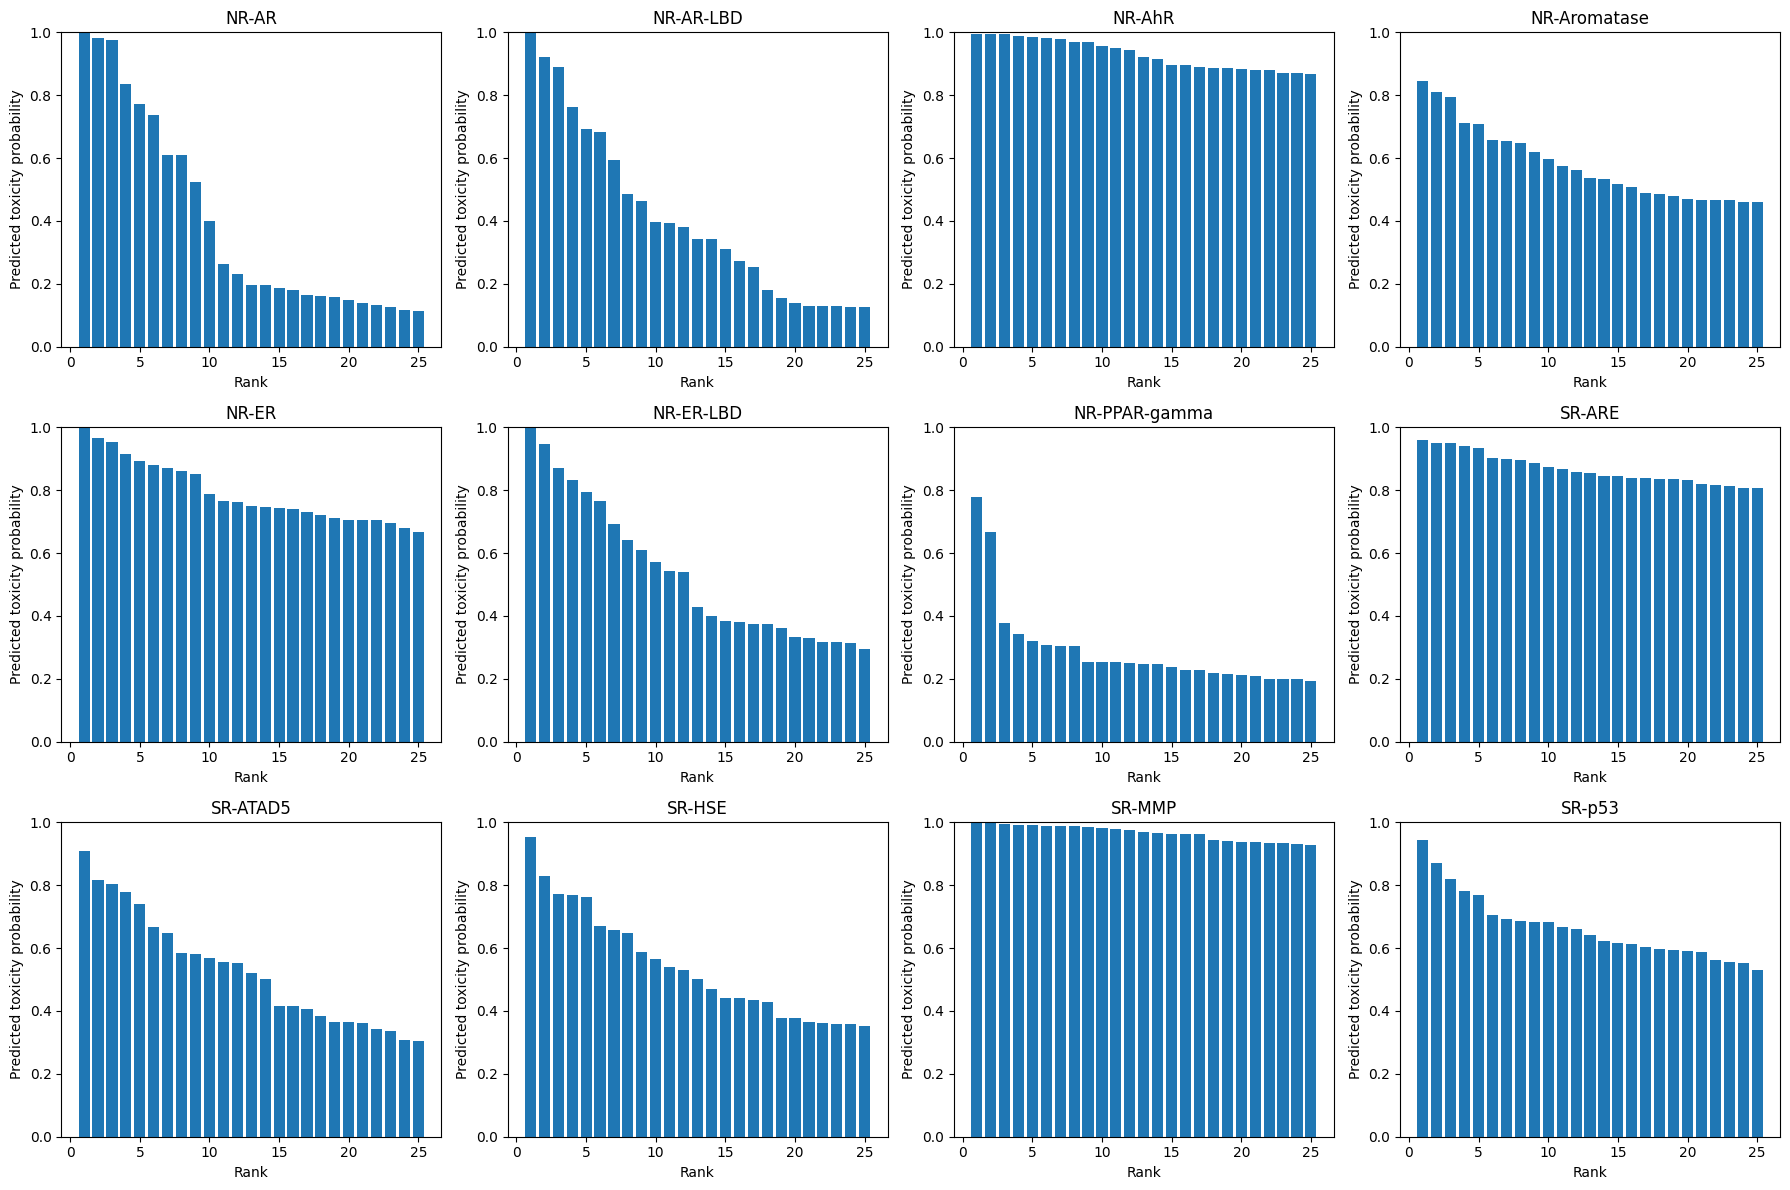

In [ ]:
fig, axes = plt.subplots(3, 4, figsize=(18, 12))
axes = axes.flatten()

for task_idx, task_name in enumerate(task_columns):
    items = top_molecules[task_name]
    probs = [item["probability"] for item in items]

    axes[task_idx].bar(
        range(1, len(probs) + 1),
        probs
    )
    axes[task_idx].set_title(task_name)
    axes[task_idx].set_xlabel("Rank")
    axes[task_idx].set_ylabel("Predicted toxicity probability")
    axes[task_idx].set_ylim(0, 1)

plt.tight_layout()
plt.show()

In [ ]:
summary = (
    perturbation_df
    .groupby("task")
    .agg(
        n_molecules=("rank", "nunique"),
        n_bond_perturbations=("bond_idx", "size"),
        mean_abs_importance=("importance", lambda x: x.abs().mean()),
        mean_importance=("importance", "mean"),
    )
    .reset_index()
)

display(summary)
summary.to_csv(f"{RESULTS_DIR}/explanation_summary.csv", index=False)

,task,n_molecules,n_bond_perturbations,mean_abs_importance,mean_importance
0,NR-AR,25,715,0.179628,0.165853
1,NR-AR-LBD,25,693,0.200925,0.183496
2,NR-AhR,25,175,0.217220,0.212888
3,NR-Aromatase,25,356,0.198800,0.187403
4,NR-ER,25,389,0.248690,0.237021
5,NR-ER-LBD,25,407,0.229459,0.198358
6,NR-PPAR-gamma,25,290,0.155305,0.128512
7,SR-ARE,25,308,0.177879,0.171258
8,SR-ATAD5,25,184,0.286466,0.283506
9,SR-HSE,25,343,0.209980,0.162533


In [ ]:
def draw_explained_molecule(task_name:str, rank:int, top_n_bonds:int=3):
  """
  Creating a visualization of the molecule with the
  important edges highted and a table of information on
  the molecule
  Parameters:
  task_name (str): Name of the task
  rank (int): Rank of the molecule
  top_n_bonds (int): Number of top bonds to highlight
  Returns:
  None
  """
    rows = top_bonds[
        (top_bonds["task"] == task_name) &
        (top_bonds["rank"] == rank)
    ].copy()

    if rows.empty:
        print(f"No explanation found for {task_name}, rank {rank}")
        return

    rows = rows.sort_values(
        "importance",
        key=lambda s: s.abs(),
        ascending=False
    ).drop_duplicates("bond_idx").head(top_n_bonds)

    smiles = rows.iloc[0]["original_smiles"]
    probability = float(rows.iloc[0]["original_probability"])
    mol = Chem.MolFromSmiles(smiles)

    if mol is None:
        print("Invalid SMILES")
        return

    highlight_bonds = []
    highlight_colors = {}

    for _, row in rows.iterrows():
        bond_idx = int(row["bond_idx"])
        if bond_idx >= mol.GetNumBonds():
            continue

        highlight_bonds.append(bond_idx)
        if row["importance"] > 0:
            highlight_colors[bond_idx] = (0.9, 0.2, 0.2)
        else:
            highlight_colors[bond_idx] = (0.2, 0.4, 0.9)

    display(HTML(
        f"<h3>{task_name} | Rank {rank} | "
        f"Predicted probability: {probability:.3f}</h3>"
        f"<p><b>SMILES:</b> <code>{smiles}</code></p>"
    ))

    pdf_path = os.path.join(RESULTS_DIR, f"{task_name}_edge_{rank}.pdf")

    drawer = rdMolDraw2D.MolDraw2DPDF(450, 320)
    drawer.drawOptions().useBWAtomPalette() # Optional styling
    drawer.DrawMolecule(
        mol,
        highlight_bonds=highlight_bonds,
        highlight_bond_colors={k: v for k, v in highlight_colors.items()}
    )
    drawer.FinishDrawing()

    with open(pdf_path, "wb") as f:
        f.write(drawer.GetDrawingText())

    print(f"Saved PDF to: {pdf_path}")

    img = Draw.MolToImage(
        mol,
        size=(450, 320),
        highlightBonds=highlight_bonds,
        highlightBondColors=highlight_colors
    )
    display(img)

    print("Highlighted bonds:")
    display(rows[["bond_idx", "atom_begin_symbol",
                  "atom_end_symbol", "bond_type", "importance"]])

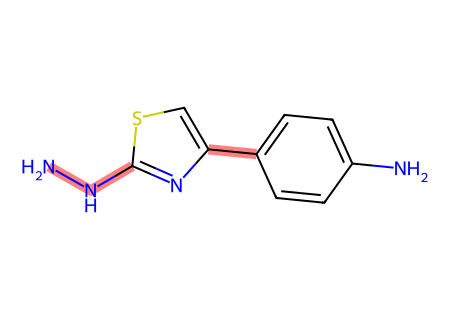

Highlighted bonds:


,bond_idx,atom_begin_symbol,atom_end_symbol,bond_type,importance
1408,0,N,N,SINGLE,0.018612
1410,4,C,C,SINGLE,0.014909
1409,1,N,C,SINGLE,0.012917


--------------------------------------------------------------------------------


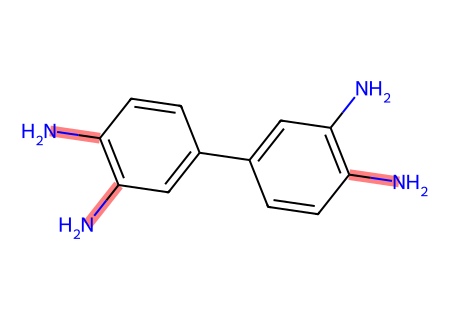

Highlighted bonds:


,bond_idx,atom_begin_symbol,atom_end_symbol,bond_type,importance
1412,0,N,C,SINGLE,0.003772
1414,8,C,N,SINGLE,0.003772
1415,10,C,N,SINGLE,0.002907


--------------------------------------------------------------------------------


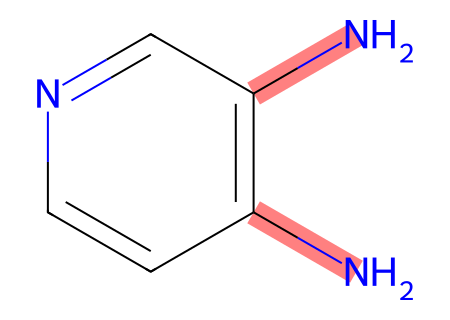

Highlighted bonds:


,bond_idx,atom_begin_symbol,atom_end_symbol,bond_type,importance
1417,0,N,C,SINGLE,0.447324
1418,6,C,N,SINGLE,0.245103


--------------------------------------------------------------------------------


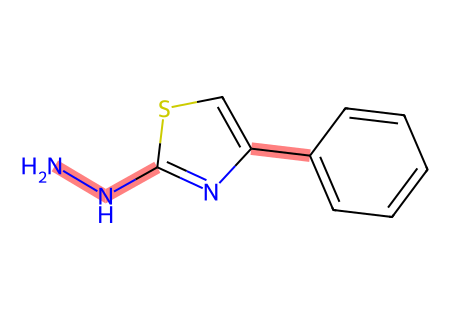

Highlighted bonds:


,bond_idx,atom_begin_symbol,atom_end_symbol,bond_type,importance
1419,0,N,N,SINGLE,0.247824
1420,1,N,C,SINGLE,0.163612
1421,4,C,C,SINGLE,0.107889


--------------------------------------------------------------------------------


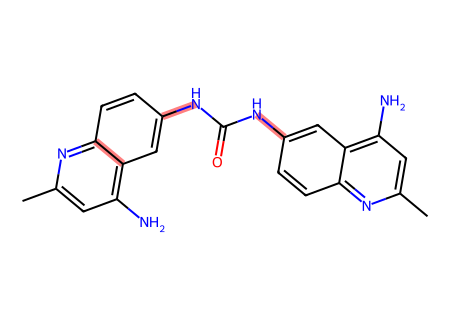

Highlighted bonds:


,bond_idx,atom_begin_symbol,atom_end_symbol,bond_type,importance
1424,7,C,N,SINGLE,0.078281
1428,11,N,C,SINGLE,0.078281
1431,28,C,C,AROMATIC,0.011828


--------------------------------------------------------------------------------


In [ ]:
from IPython.display import display, HTML
def plot_task_molecules(task_name, top_k=5, top_n_bonds=3):
    available_ranks = sorted(
        top_molecules[task_name],
        key=lambda x: x["rank"]
    )[:top_k]

    for item in available_ranks:
        draw_explained_molecule(
            task_name=task_name,
            rank=item["rank"],
            top_n_bonds=top_n_bonds
        )
        print("-" * 80)

plot_task_molecules("NR-AhR", top_k=5)

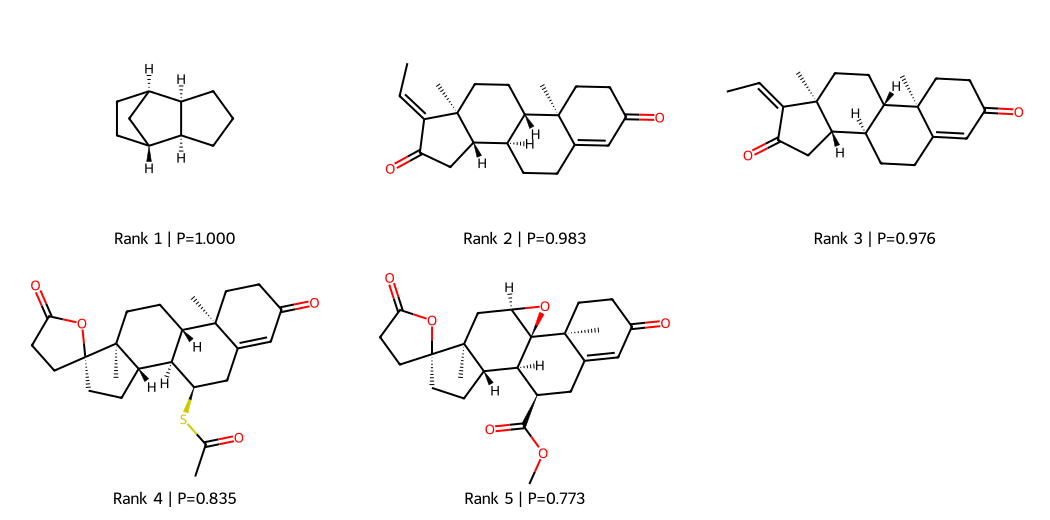

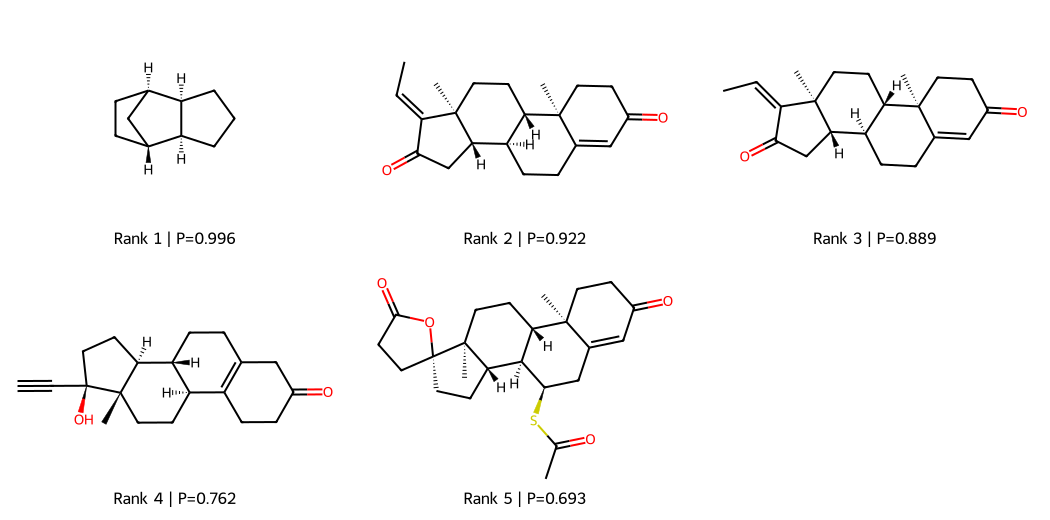

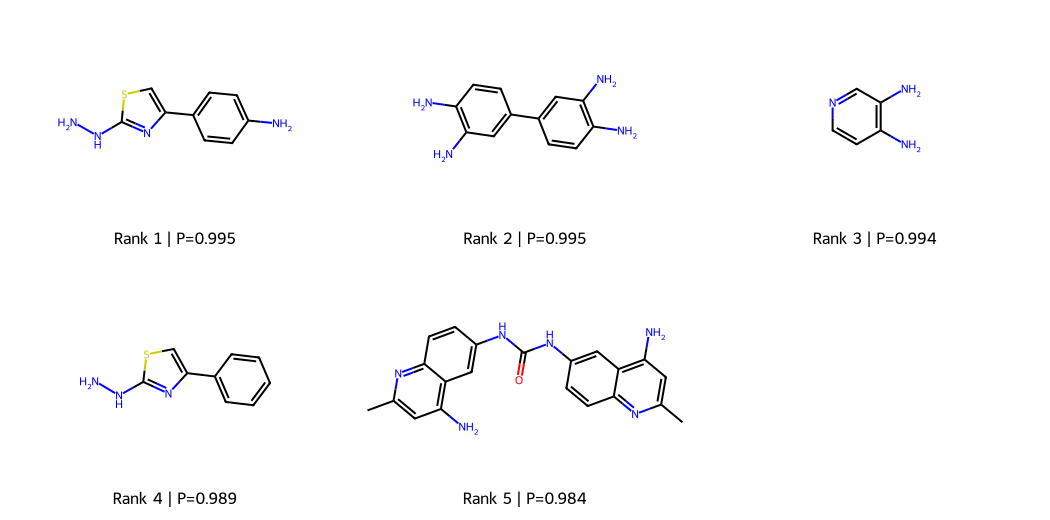

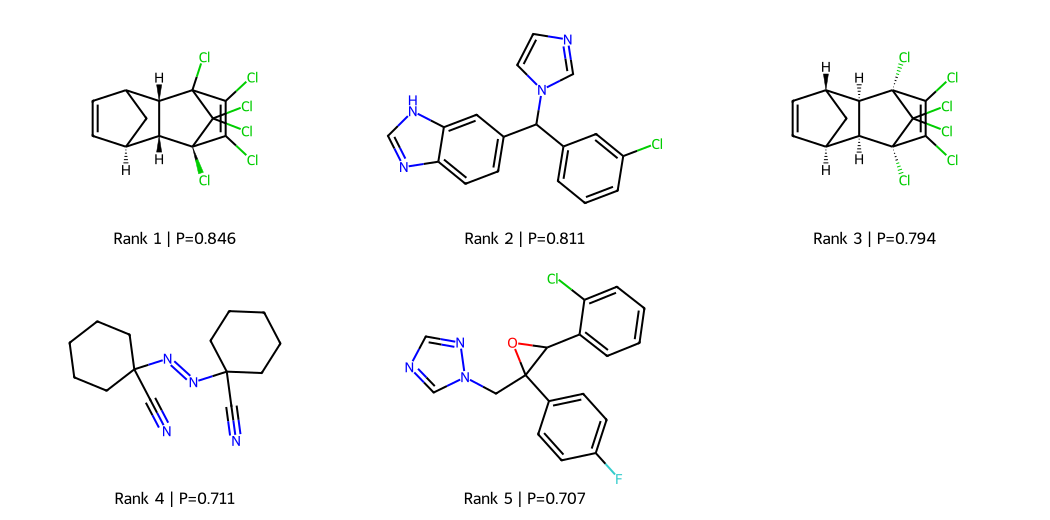

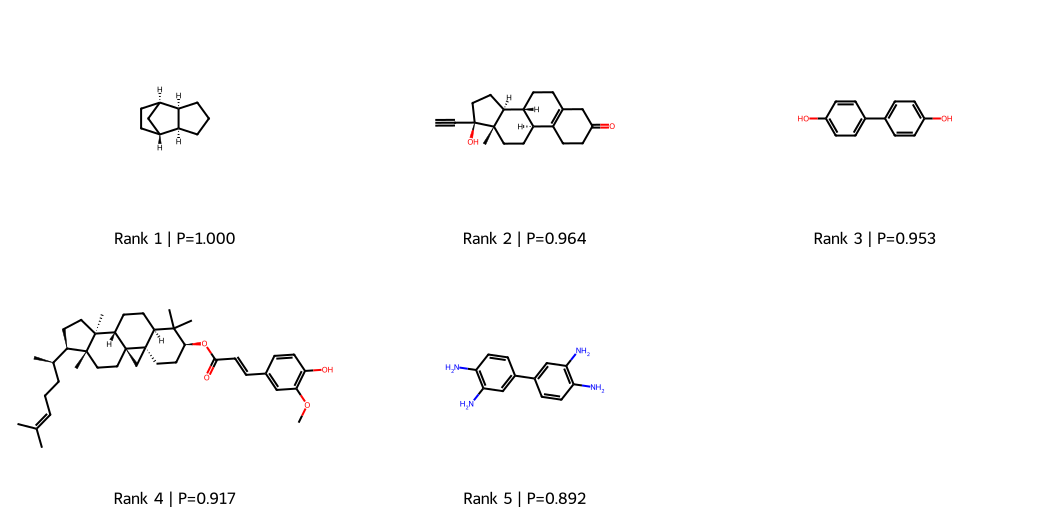

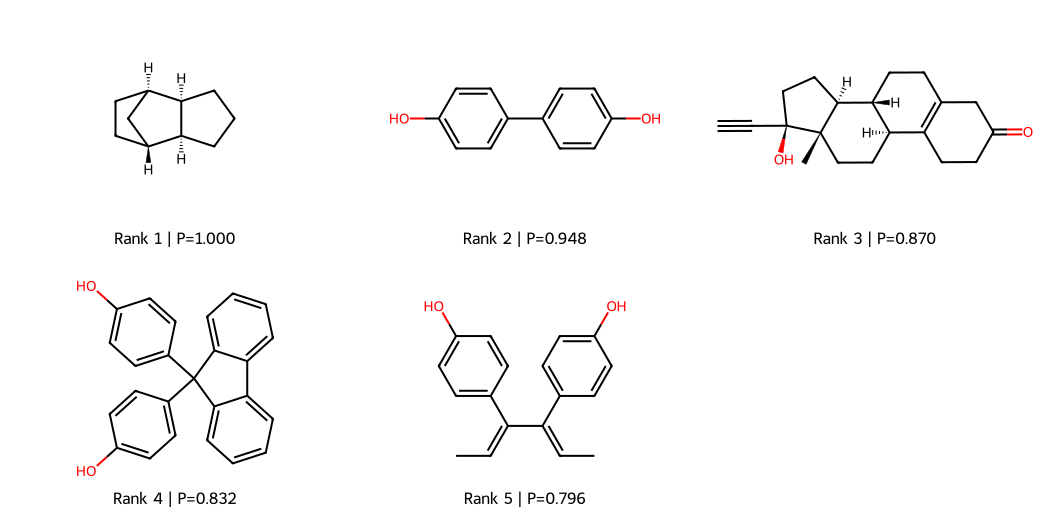

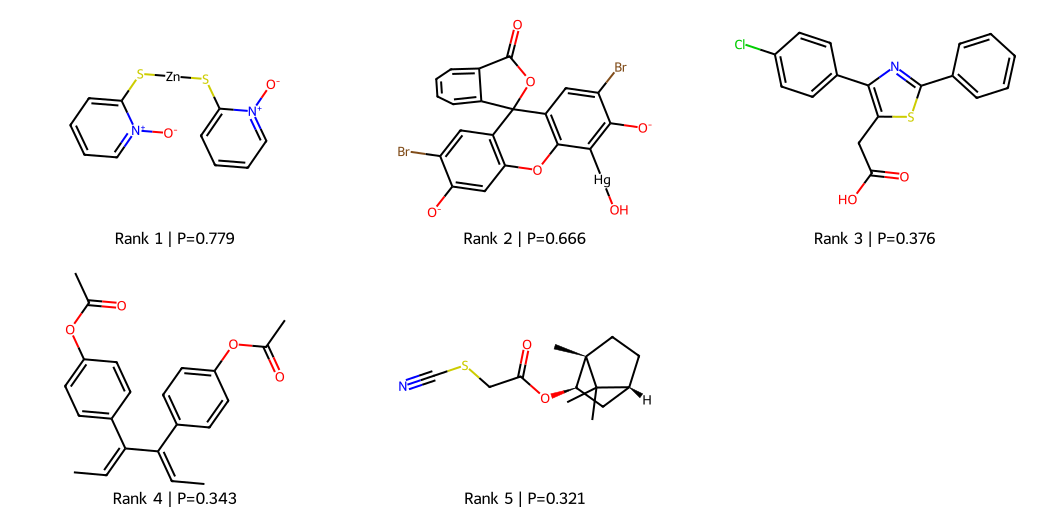

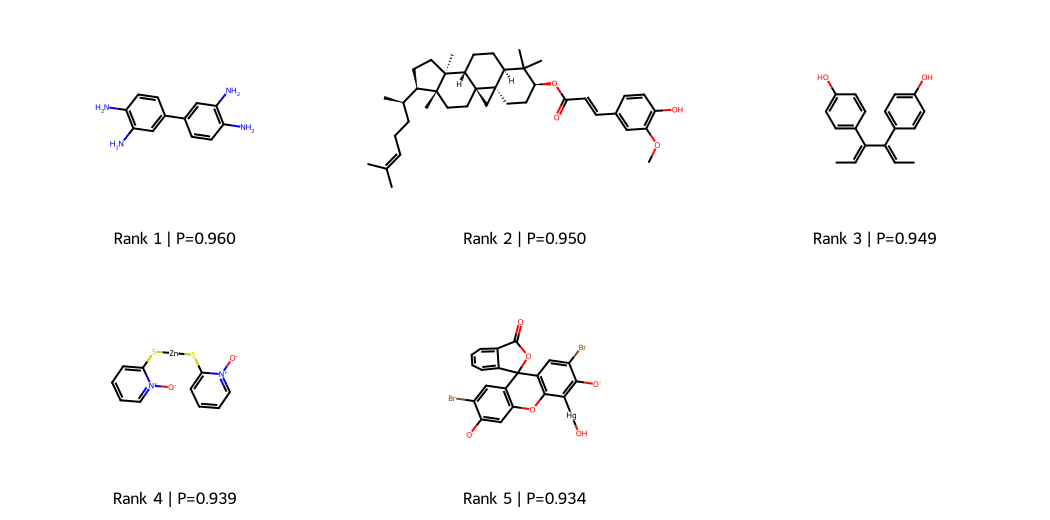

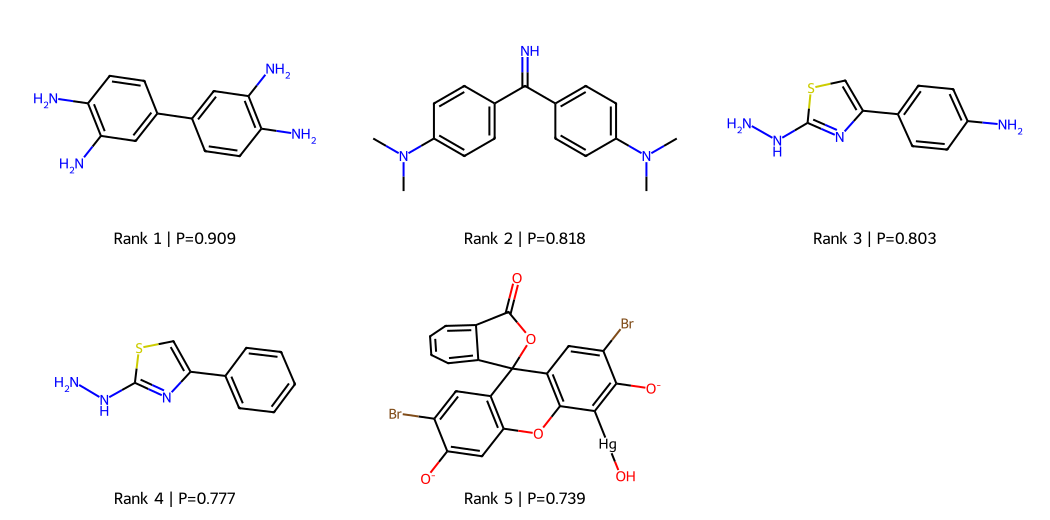

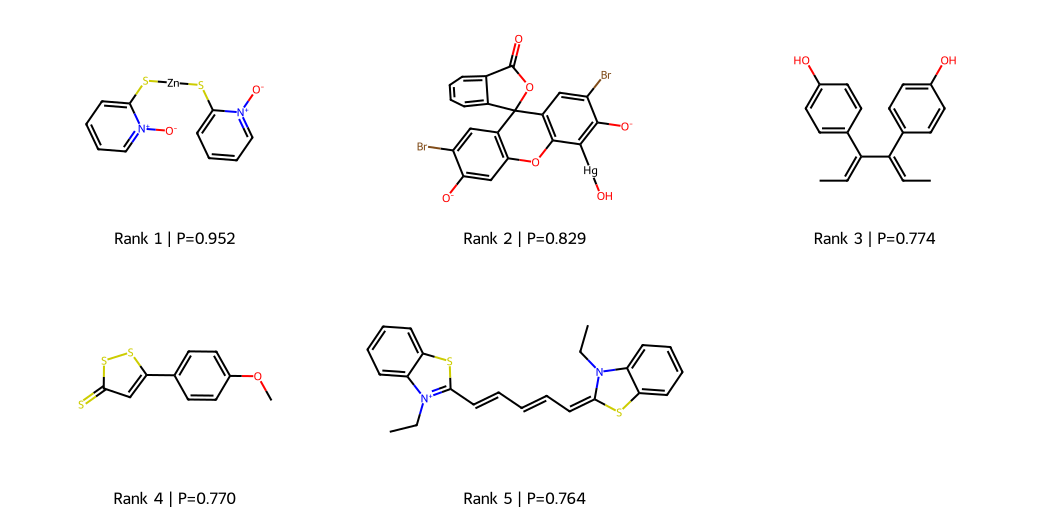

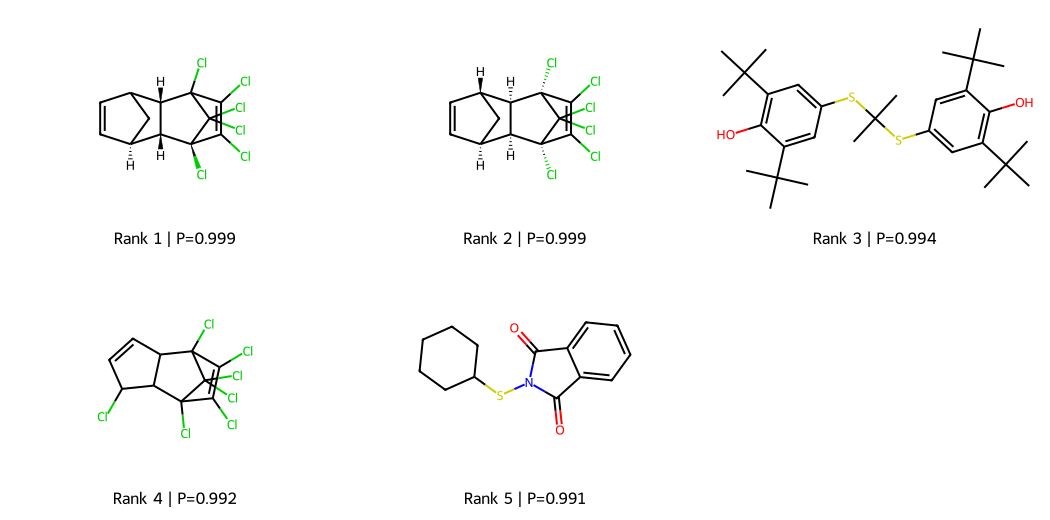

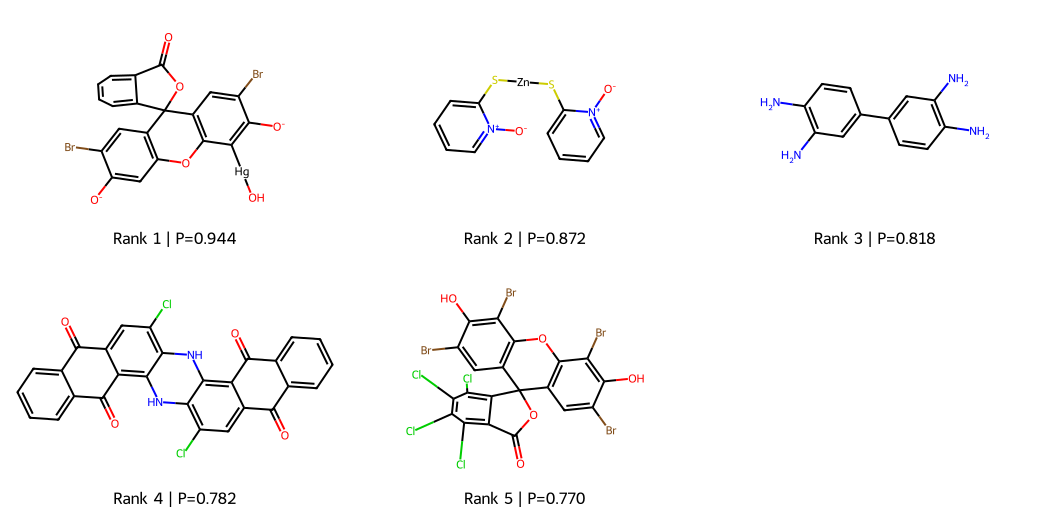

In [ ]:
import io
from PIL import Image

for task_name, items in top_molecules.items():
    items = sorted(items, key=lambda x: x["rank"])[:5]

    legends = [
        f"Rank {item['rank']} | P={item['probability']:.3f}"
        for item in items
    ]

    mols = [Chem.MolFromSmiles(item["smiles"]) for item in items]

    valid = [
        (mol, legend)
        for mol, legend in zip(mols, legends)
        if mol is not None
    ]

    if not valid:
        continue

    sheet = Draw.MolsToGridImage(
        [x[0] for x in valid],
        legends=[x[1] for x in valid],
        molsPerRow=3,
        subImgSize=(350, 260),
        useSVG=False
    )

    output_path = os.path.join(
        RESULTS_DIR, f"{task_name.replace('/', '_')}_top5.pdf"
    )

    if hasattr(sheet, "data"):
        pil_img = Image.open(io.BytesIO(sheet.data))
    else:
        pil_img = sheet

    pil_img.convert("RGB").save(output_path, "PDF", resolution=300)
    display(HTML(f"<h2>{task_name}</h2>"))
    display(sheet)